# Choosing a financial clock

Each market record contains a time, price, and volume, and their product is its dollar value:

$$
(t_i,p_i,v_i)_{i=1}^{n},\qquad d_i=p_iv_i.
$$

Here, $i$ labels a record; $n$ is the number of records; $t_i$ is time; $p_i$ is price; $v_i$ is traded volume. $d_i=p_iv_i$ is the dollar value assigned to record $i.$

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("05_event_based_financial_time");
using CSV, Printf
using RiskLabAI.Data: StandardBars,TimeBars,FixedImbalanceBars,ExpectedImbalanceBars,FixedRunBars,ExpectedRunBars,Tick,Volume,Dollar,construct_bars_from_data
using RiskLabAI.Utils: CUMULATIVE_TICKS,CUMULATIVE_THETA,EXPECTED_IMBALANCE,EXPECTED_TICKS_NUMBER,CUMULATIVE_BUY_THETA,CUMULATIVE_SELL_THETA,EXPECTED_BUY_IMBALANCE,EXPECTED_SELL_IMBALANCE,EXPECTED_BUY_TICKS_PROPORTION
raw_all = load_binance()
raw = first(raw_all,10080)
data_path = dataset_path("binance_btcusdt")
@assert isfile(data_path)
observations = select(raw,:time,:close,:volume)
bar_columns = ["Time","Last record","Open","High","Low","Close","Volume","Buy volume","Sell volume","Records","Dollar value","Rule level"]

function bar_frame(rows)
    return DataFrame([name=>(j==1 ? DateTime[row[j] for row in rows] : j in (2,10) ? Int[row[j] for row in rows] : Float64[row[j] for row in rows]) for (j,name) in enumerate(bar_columns)])
end

function history_frame(rule,names)
    history = rule.analyse_thresholds
    columns = Pair["Record"=>collect(eachindex(history))]
    append!(columns,[name=>Float64[row[name] for row in history] for name in names])
    return DataFrame(columns)
end


history_frame (generic function with 1 method)

## Four Ways to Measure Progress

A tick bar ends after a chosen number of records, while a volume bar ends when accumulated volume first reaches its threshold:

$$
\tau_k^{\mathrm{tick}}=\inf\left\{n>\tau_{k-1}:n-\tau_{k-1}\geq h_N\right\},\quad
\tau_k^{\mathrm{volume}}=\inf\left\{n>\tau_{k-1}:\sum_{i=\tau_{k-1}+1}^{n}v_i\geq h_V\right\},
$$

Here, $\tau_k$ is the ending record of bar $k$; $\tau_{k-1}$ is the preceding ending record; $n$ is a candidate ending record. $h_N$ is the required record count; $v_i$ is volume in record $i$; $h_V$ is the volume threshold; $\inf$ selects the first qualifying record.

A dollar bar ends when accumulated price times volume first reaches a chosen dollar threshold:

$$
\tau_k^{\mathrm{dollar}}=\inf\left\{n>\tau_{k-1}:\sum_{i=\tau_{k-1}+1}^{n}p_iv_i\geq h_D\right\}.
$$

Here, $\tau_k^{\mathrm{dollar}}$ is the ending record of dollar bar $k$; $\tau_{k-1}$ is the previous ending record. $n$ is a candidate ending record; $p_i$ is price; $v_i$ is volume; $h_D$ is the dollar threshold; $\inf$ selects the first crossing.

In [2]:
target_bars = 336
tick_level = nrow(raw)/target_bars
volume_level = sum(raw.volume)/target_bars
dollar_level = sum(raw.close.*raw.volume)/target_bars
clock_names = ["Clock time","Tick time","Volume time","Dollar time"]
bars = Dict("Clock time"=>bar_frame(construct_bars_from_data(TimeBars(;resolution_type="MIN",resolution_units=30);data=observations)),
    "Tick time"=>bar_frame(construct_bars_from_data(StandardBars{Tick}(;bar_type="tick",threshold=tick_level);data=observations)),
    "Volume time"=>bar_frame(construct_bars_from_data(StandardBars{Volume}(;bar_type="volume",threshold=volume_level);data=observations)),
    "Dollar time"=>bar_frame(construct_bars_from_data(StandardBars{Dollar}(;bar_type="dollar",threshold=dollar_level);data=observations)))
provenance = DataFrame("Item"=>["Provider","Archive","Public access","Market","First record","Last record","Records used","Basic record"],"Value"=>["Binance Data Vision","BTCUSDT-1m-2021-01.zip","Direct public download","Bitcoin quoted in USDT",string(first(raw.time)),string(last(raw.time)),string(nrow(raw)),"One-minute spot interval"])
save_table(provenance,paths,"data_provenance";caption="Source and limits of the public Binance illustration.",label="tab:chapter4-data-provenance")
save_data(observations,paths,"one_week_observations")
for (name,stem) in zip(clock_names,["clock","tick","volume","dollar"])
    save_data(bars[name],paths,stem*"_bars")
end


Row,Item,Value
,String,String
1,Provider,Binance Data Vision
2,Archive,BTCUSDT-1m-2021-01.zip
3,Public access,Direct public download
4,Market,Bitcoin quoted in USDT
5,First record,2021-01-01T00:00:00
6,Last record,2021-01-07T23:59:00
7,Records used,10080
8,Basic record,One-minute spot interval


In [3]:
levels = Dict("Clock time"=>"30 minutes","Tick time"=>@sprintf("%.0f records",tick_level),"Volume time"=>@sprintf("%.3f BTC",volume_level),"Dollar time"=>@sprintf("USDT %.2f",dollar_level))
summary_rows = NamedTuple[]
start_time = first(raw.time)-Minute(1)
for name in clock_names
    frame = bars[name]
    previous_times = vcat(start_time,frame.Time[1:end-1])
    duration = Dates.value.(frame.Time.-previous_times)./60000
    excess = name=="Tick time" ? (frame.Records.-tick_level)./tick_level : name=="Volume time" ? (frame.Volume.-volume_level)./volume_level : name=="Dollar time" ? (frame[!,"Dollar value"].-dollar_level)./dollar_level : zeros(nrow(frame))
    push!(summary_rows,(;name,rule=levels[name],complete=nrow(frame),median_records=median(frame.Records),median_minutes=median(duration),mean_excess=100mean(excess)))
end
standard_bar_summary = DataFrame(summary_rows)
rename!(standard_bar_summary,["Measure of progress","Rule","Complete bars","Median records","Median minutes","Mean excess over rule (%)"])
save_table(standard_bar_summary,paths,"standard_bar_summary";caption="Four bar rules applied to the same 10,080 one-minute records.",label="tab:standard-bar-summary")


Row,Measure of progress,Rule,Complete bars,Median records,Median minutes,Mean excess over rule (%)
,String,String,Int64,Float64,Float64,Float64
1,Clock time,30 minutes,335,30.0,30.0,0.0
2,Tick time,30 records,336,30.0,30.0,0.0
3,Volume time,2446.575 BTC,325,28.0,28.0,3.16483
4,Dollar time,USDT 81498376.55,324,28.0,28.0,3.49323


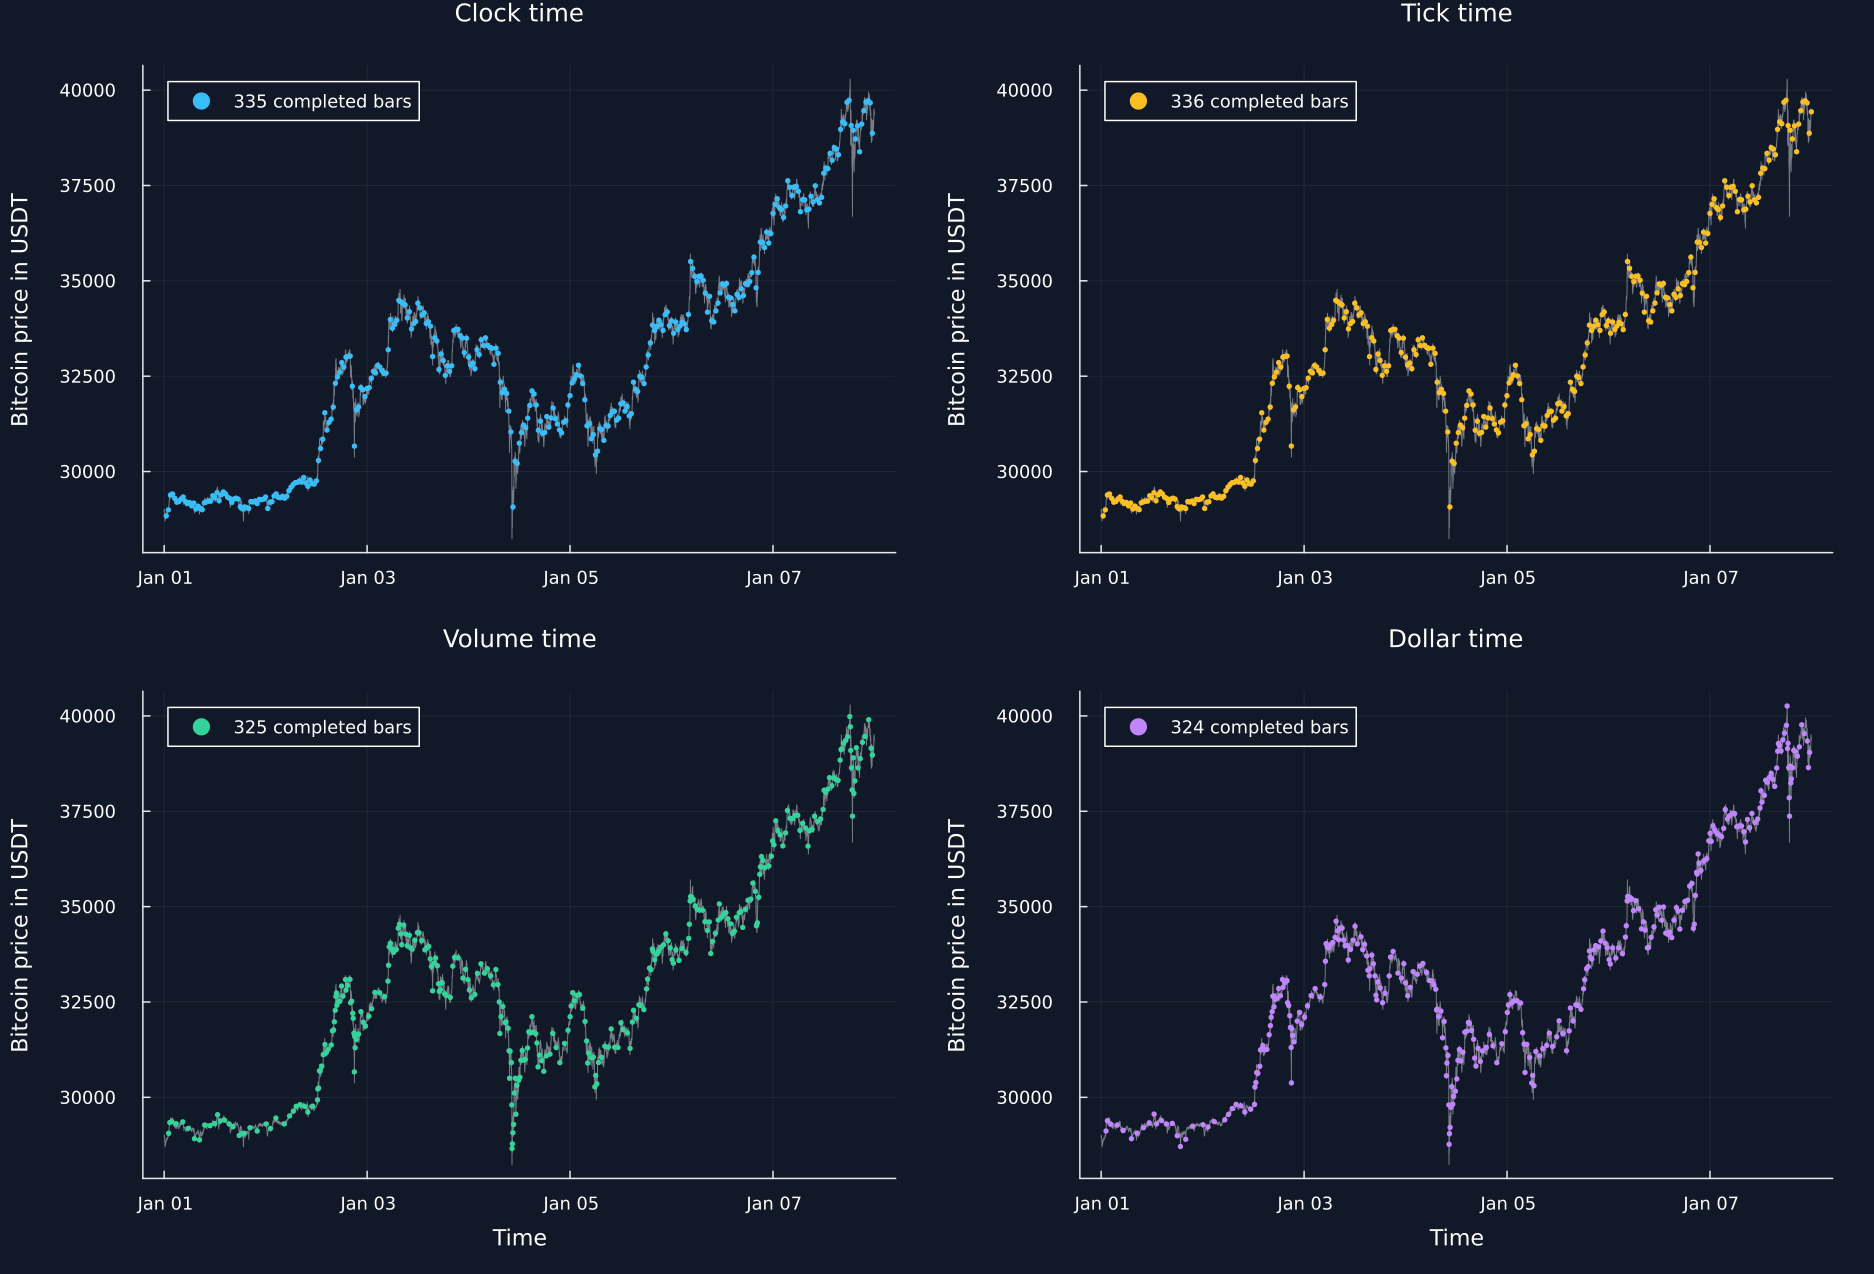

In [4]:
colors = [palette.cyan,palette.amber,palette.green,"#C084FC"]
clock_ticks = collect(DateTime(2021,1,1):Day(2):DateTime(2021,1,7))
panels = []
for (index,name) in enumerate(clock_names)
    frame = bars[name]
    panel = plot(raw.time,raw.close;color=palette.text,alpha=.48,linewidth=.65,title=name,ylabel="Bitcoin price in USDT",xlabel=index>2 ? "Time" : "",xticks=(clock_ticks,Dates.format.(clock_ticks,dateformat"u dd")),label=false,legend=:topleft)
    scatter!(panel,frame.Time,frame.Close;color=colors[index],markersize=2,markerstrokewidth=0,label=string(nrow(frame)," completed bars"))
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(2,2),size=(1250,850)),paths,"four_financial_clocks")


## Unequal Activity

A completed bar may pass its threshold, but the excess is smaller than the final record that caused the crossing:

$$
0\leq \sum_{i=\tau_{k-1}+1}^{\tau_k}v_i-h_V<v_{\tau_k},\qquad
0\leq \sum_{i=\tau_{k-1}+1}^{\tau_k}p_iv_i-h_D<p_{\tau_k}v_{\tau_k}.
$$

Here, $k$ labels the bar; $\tau_{k-1}+1$ and $\tau_k$ are its first and last records; $v_i$ is volume; $p_i$ is price. $h_V$ is the volume threshold; $h_D$ is the dollar threshold; $v_{\tau_k}$ and $p_{\tau_k}v_{\tau_k}$ are the final volume and dollar contributions.

Row,Measure of progress,Smallest record count,Middle record count,Largest record count,Standard deviation divided by mean
,String,Float64,Float64,Float64,Float64
1,Clock time,30.0,30.0,30.0,0.0
2,Tick time,30.0,30.0,30.0,0.0
3,Volume time,3.0,28.0,129.0,0.613158
4,Dollar time,4.0,28.0,150.0,0.662719


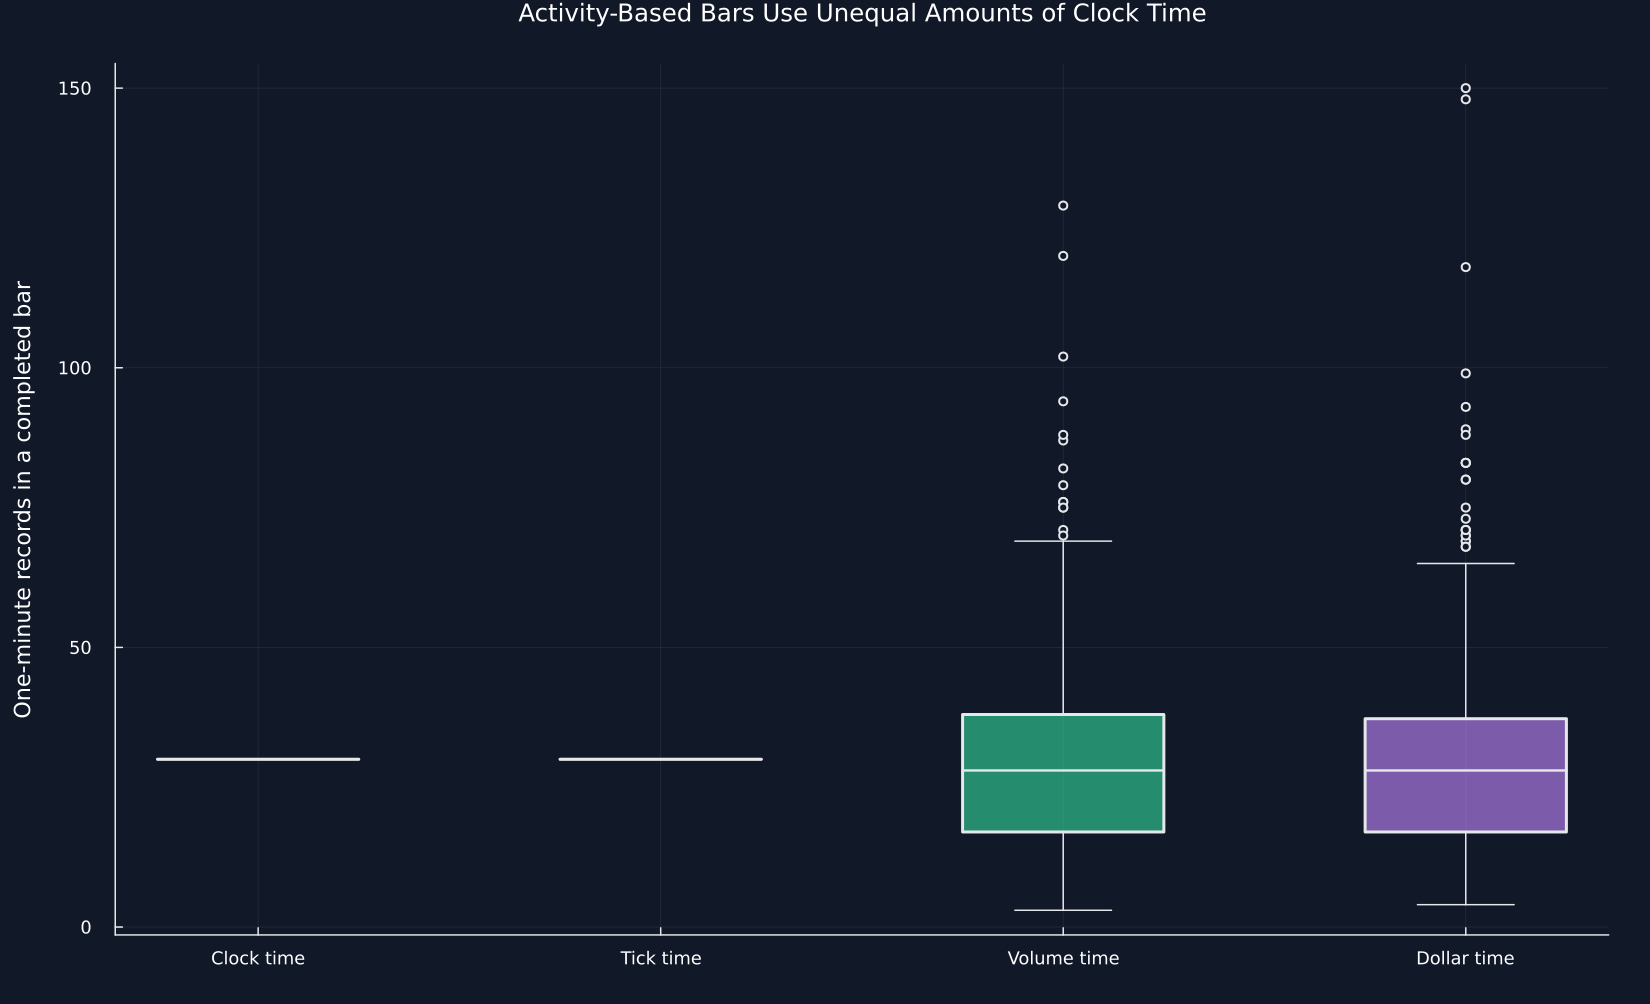

In [5]:
dispersion_rows = NamedTuple[]
for name in clock_names
    counts = Float64.(bars[name].Records)
    push!(dispersion_rows,(;name,smallest=minimum(counts),middle=median(counts),largest=maximum(counts),relative_deviation=std(counts)/mean(counts)))
end
standard_bar_dispersion = DataFrame(dispersion_rows)
rename!(standard_bar_dispersion,["Measure of progress","Smallest record count","Middle record count","Largest record count","Standard deviation divided by mean"])
save_table(standard_bar_dispersion,paths,"standard_bar_dispersion";caption="Variation in the number of one-minute records contained in each completed bar.",label="tab:standard-bar-dispersion")
figure = plot(;xticks=(1:4,clock_names),ylabel="One-minute records in a completed bar",title="Activity-Based Bars Use Unequal Amounts of Clock Time",legend=false,size=(1100,670))
for (index,name) in enumerate(clock_names)
    values = bars[name].Records
    lower,middle,upper = quantile(values,[.25,.5,.75])
    spread = upper-lower
    bottom = minimum(values[values.>=lower-1.5spread])
    top = maximum(values[values.<=upper+1.5spread])
    plot!(figure,Shape([index-.25,index+.25,index+.25,index-.25],[lower,lower,upper,upper]);color=colors[index],fillalpha=.62,linecolor=palette.text)
    plot!(figure,[index-.25,index+.25],[middle,middle];color=palette.text,linewidth=1.6)
    plot!(figure,[index,index],[bottom,lower];color=palette.text,linewidth=1)
    plot!(figure,[index,index],[upper,top];color=palette.text,linewidth=1)
    for height in (bottom,top)
        plot!(figure,[index-.12,index+.12],[height,height];color=palette.text,linewidth=1)
    end
    fliers = values[(values.<bottom).|(values.>top)]
    scatter!(figure,fill(index,length(fliers)),fliers;markercolor=palette.background,markerstrokecolor=palette.text,markersize=3)
end
save_figure(figure,paths,"records_per_bar")


## Tests

In [6]:
@assert nrow(raw) == 10080
@assert issorted(raw.time)
@assert all(isfinite,Matrix(raw[:,[:close,:volume]]))
@assert all(raw.close.>0)
@assert all(raw.volume.>=0)
@assert nrow(bars["Clock time"]) == 335
@assert nrow(bars["Tick time"]) == 336
@assert nrow(bars["Volume time"]) == 325
@assert nrow(bars["Dollar time"]) == 324
@assert all(bars["Tick time"].Records.==30)
@assert all(bars["Volume time"].Volume.>=volume_level)
@assert all(bars["Dollar time"][!,"Dollar value"].>=dollar_level)
volume_closing_records = bars["Volume time"][!,"Last record"]
dollar_closing_records = bars["Dollar time"][!,"Last record"]
@assert all(bars["Volume time"].Volume.-volume_level.<raw.volume[volume_closing_records].+1e-12)
@assert all(bars["Dollar time"][!,"Dollar value"].-dollar_level.<(raw.close[dollar_closing_records].*raw.volume[dollar_closing_records]).+1e-8)
@assert all(standard_bar_summary[!,"Complete bars"].>300)
@assert standard_bar_dispersion[standard_bar_dispersion[!,"Measure of progress"].=="Tick time","Standard deviation divided by mean"][1] == 0
@assert standard_bar_dispersion[standard_bar_dispersion[!,"Measure of progress"].=="Volume time","Standard deviation divided by mean"][1] > 0
@assert standard_bar_dispersion[standard_bar_dispersion[!,"Measure of progress"].=="Dollar time","Standard deviation divided by mean"][1] > 0
@assert isfile(joinpath(paths.figures,"four_financial_clocks.pdf"))
@assert isfile(joinpath(paths.figures,"records_per_bar.pdf"))
@assert isfile(joinpath(paths.tables,"data_provenance.tex"))
@assert isfile(joinpath(paths.tables,"standard_bar_summary.tex"))
@assert isfile(joinpath(paths.tables,"standard_bar_dispersion.tex"))
